# Benchmark Diversity & Comprehensiveness Analysis

This notebook computes **Diversity** (semantic, structural, complexity spread) and **Comprehensiveness** (class / property / feature coverage) metrics for two NL2SPARQL benchmarks, and generates three publication-ready figures.

In [1]:
import os, json

# Prevent tokenizers / OpenMP from crashing the kernel on macOS
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

from sentence_transformers import SentenceTransformer

from metrics import measure_diversity, measure_comprehensiveness, measure_redundancy
from plots import plot_semantic_embeddings, plot_structural_diversity, plot_comprehensiveness_radar, plot_coverage_table

os.makedirs("figures", exist_ok=True)

sbert = SentenceTransformer("BAAI/bge-large-en-v1.5")

## 1. Load Benchmark Data
Provide the paths to the two JSONL benchmark files and the KG name (must match a directory under `kgs_data/`).

In [2]:
import random
random.seed(42)

# ---- Configuration --------------------------------------------------------
f1 = "ABSTAT/subgraphs_output/qa_output/04-06-22-dbpedia-qlever-gpt5_optimal_sample100.jsonl"
f2 = "ABSTAT/subgraphs_output/qa_output/lcquad-test.jsonl"

label1 = "QueryBloom"
label2 = "Baseline"

kg_name = "dbpedia"        # directory name under kgs_data/
endpoint = "dbpedia"          # SPARQL endpoint alias for entity-type resolution
query_endpoint = "dbpedia-qlever"  # endpoint used to execute queries for result-row counts
# ---------------------------------------------------------------------------

project_root = os.path.abspath(os.path.join(os.getcwd(), "../../"))

def load_data(filepath):
    full_path = os.path.join(project_root, filepath)
    with open(full_path, "r") as f:
        return [json.loads(line) for line in f]

data1 = load_data(f1)
data2 = load_data(f2)

# Balance: downsample the larger set to match the smaller one
target_size = min(len(data1), len(data2))
if len(data1) > target_size:
    data1 = random.sample(data1, target_size)
elif len(data2) > target_size:
    data2 = random.sample(data2, target_size)

queries1  = [d["sparql"]   for d in data1 if "sparql"   in d]
queries2  = [d["sparql"]   for d in data2 if "sparql"   in d]
questions1 = [d["question"] for d in data1 if "question" in d]
questions2 = [d["question"] for d in data2 if "question" in d]

print(f"{label1}: {len(data1)} samples,  {label2}: {len(data2)} samples")


QueryBloom: 100 samples,  Baseline: 100 samples


## 2. Compute Metrics

Run all diversity and comprehensiveness metrics in one pass per benchmark.

In [3]:
print("Computing diversity metrics …")
div1 = measure_diversity(queries1, questions1, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint)
div2 = measure_diversity(queries2, questions2, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint)

print("Computing comprehensiveness metrics …")
comp1 = measure_comprehensiveness(queries1, kg_name, endpoint=endpoint)
comp2 = measure_comprehensiveness(queries2, kg_name, endpoint=endpoint)

print("Computing redundancy metrics …")
red1 = measure_redundancy(queries1, endpoint=query_endpoint)
red2 = measure_redundancy(queries2, endpoint=query_endpoint)

# Quick summary
for lbl, d, c in [(label1, div1, comp1), (label2, div2, comp2)]:
    print(f"\n--- {lbl} ---")
    for k, v in {**d, **c}.items():
        if not k.startswith("_"):
            print(f"  {k}: {v}")

Computing diversity metrics …
Computing comprehensiveness metrics …
Computing redundancy metrics …
  Redundancy: executing 344 unique queries …
  Redundancy: executing 192 unique queries …

--- QueryBloom ---
  apd: 0.5625
  mnnd: 0.3922
  unique_template_ratio: 1.0
  entity_diversity_ratio: 0.7188
  feature_entropy: 3.1719
  operator_count_std: 1.8488
  result_count_std: 8.4255
  column_count_std: 1.0085
  class_coverage: 0.0003
  class_coverage_raw: 122/483627
  property_coverage: 0.0018
  property_coverage_raw: 96/54793
  feature_coverage: 0.9231
  feature_coverage_raw: 12/13
  n_queries: 100
  n_bench_classes: 122
  n_bench_properties: 96

--- Baseline ---
  apd: 0.5631
  mnnd: 0.3936
  unique_template_ratio: 0.5
  entity_diversity_ratio: 0.9699
  feature_entropy: 1.45
  operator_count_std: 0.4308
  result_count_std: 617.1219
  column_count_std: 0.196
  class_coverage: 0.0003
  class_coverage_raw: 136/483627
  property_coverage: 0.0023
  property_coverage_raw: 125/54793
  feature_c

## Figure 1 — Semantic Diversity (t-SNE)

Side-by-side t-SNE projections of NL questions, annotated with APD and MNND.

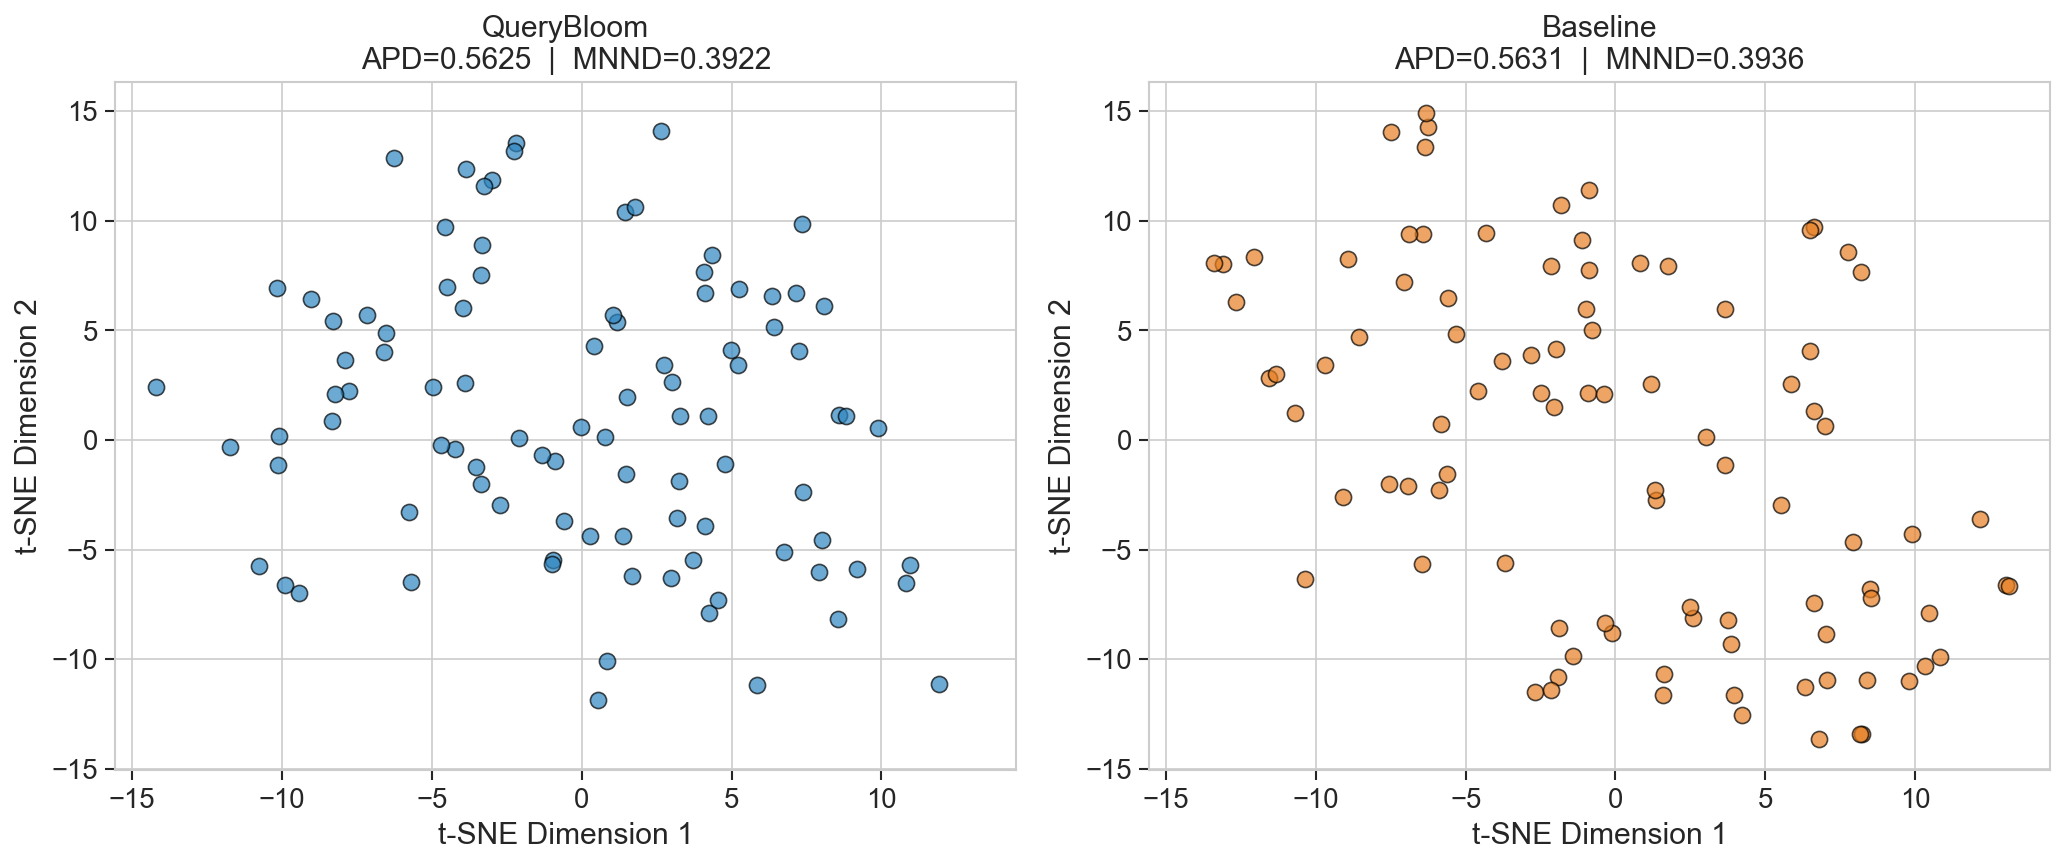

In [4]:
plot_semantic_embeddings(div1, div2, label1, label2)

## Figure 2 — Structural & Complexity Diversity

Three panels: (a) SPARQL feature distribution bars, (b) complexity-spread violins, (c) template / entity diversity scalars.

/Users/essamwisam/Desktop/UTA/Projects/NL2SparQL/misc/grasp/ABSTAT/analyze/plots/diversity_plots.py:481: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


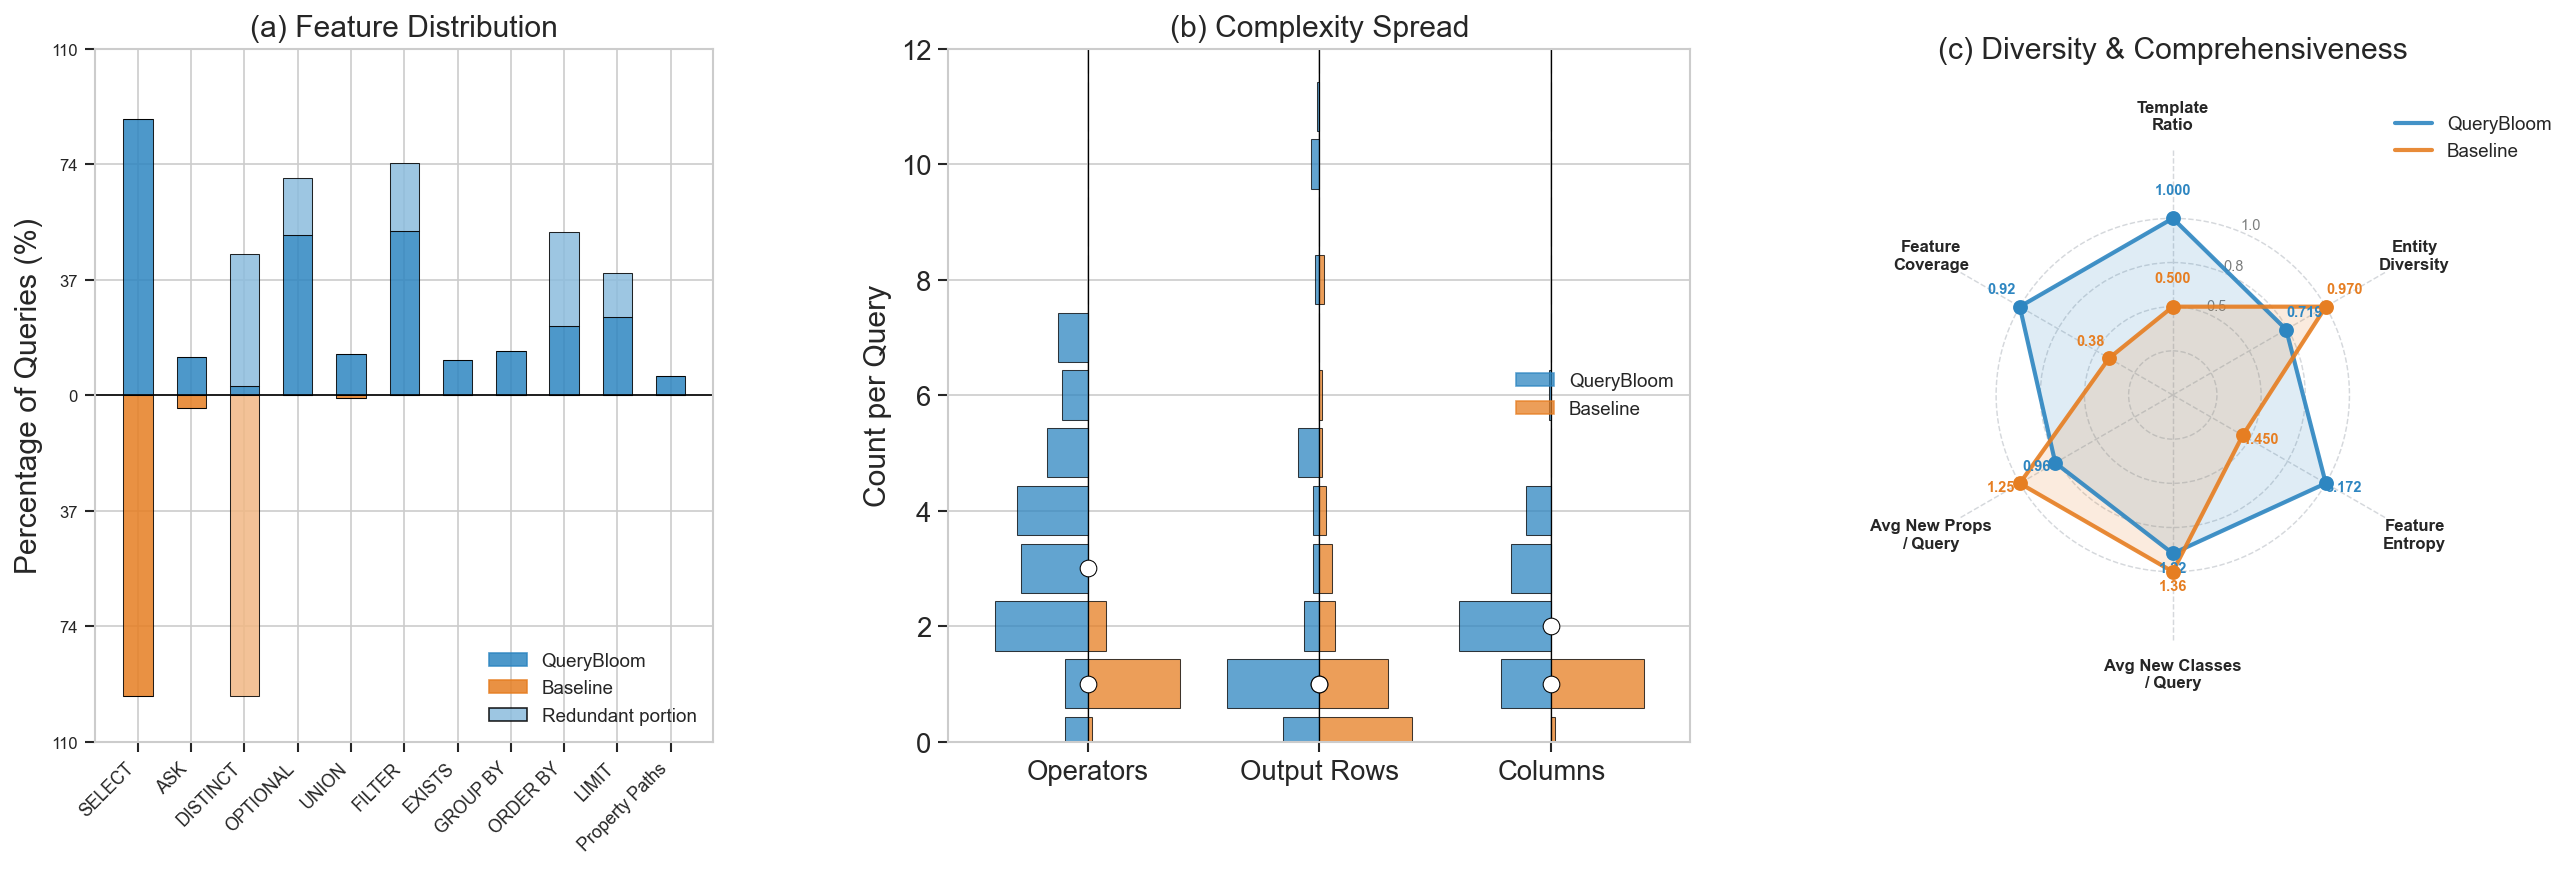

In [5]:
plot_structural_diversity(div1, div2, label1, label2, red1=red1, red2=red2, comp1=comp1, comp2=comp2)

## Figure 3 — Comprehensiveness Radar

3-spoke radar showing Class Coverage, Property Coverage, and Feature Coverage against the KG ontology.

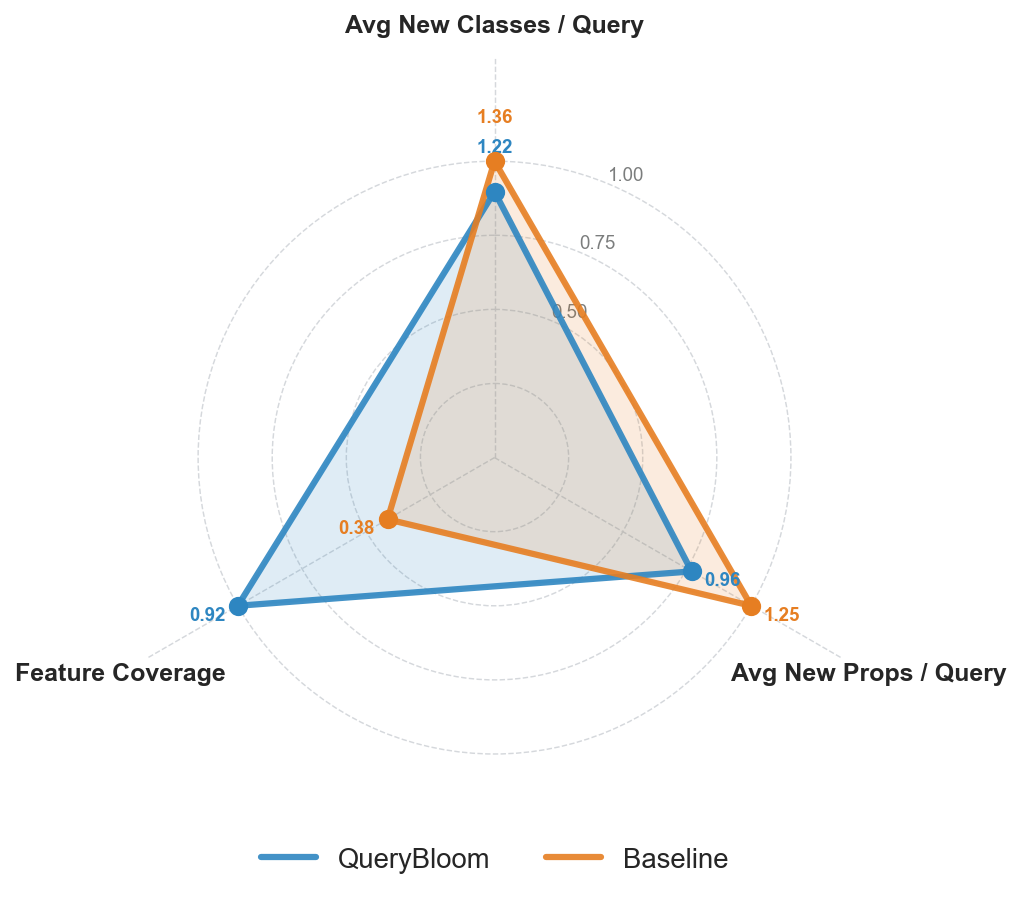

In [6]:
plot_comprehensiveness_radar(comp1, comp2, label1, label2)

## Figure 3b — Coverage Gaps Table

Random sample of classes and properties unique to one benchmark or missing from both.

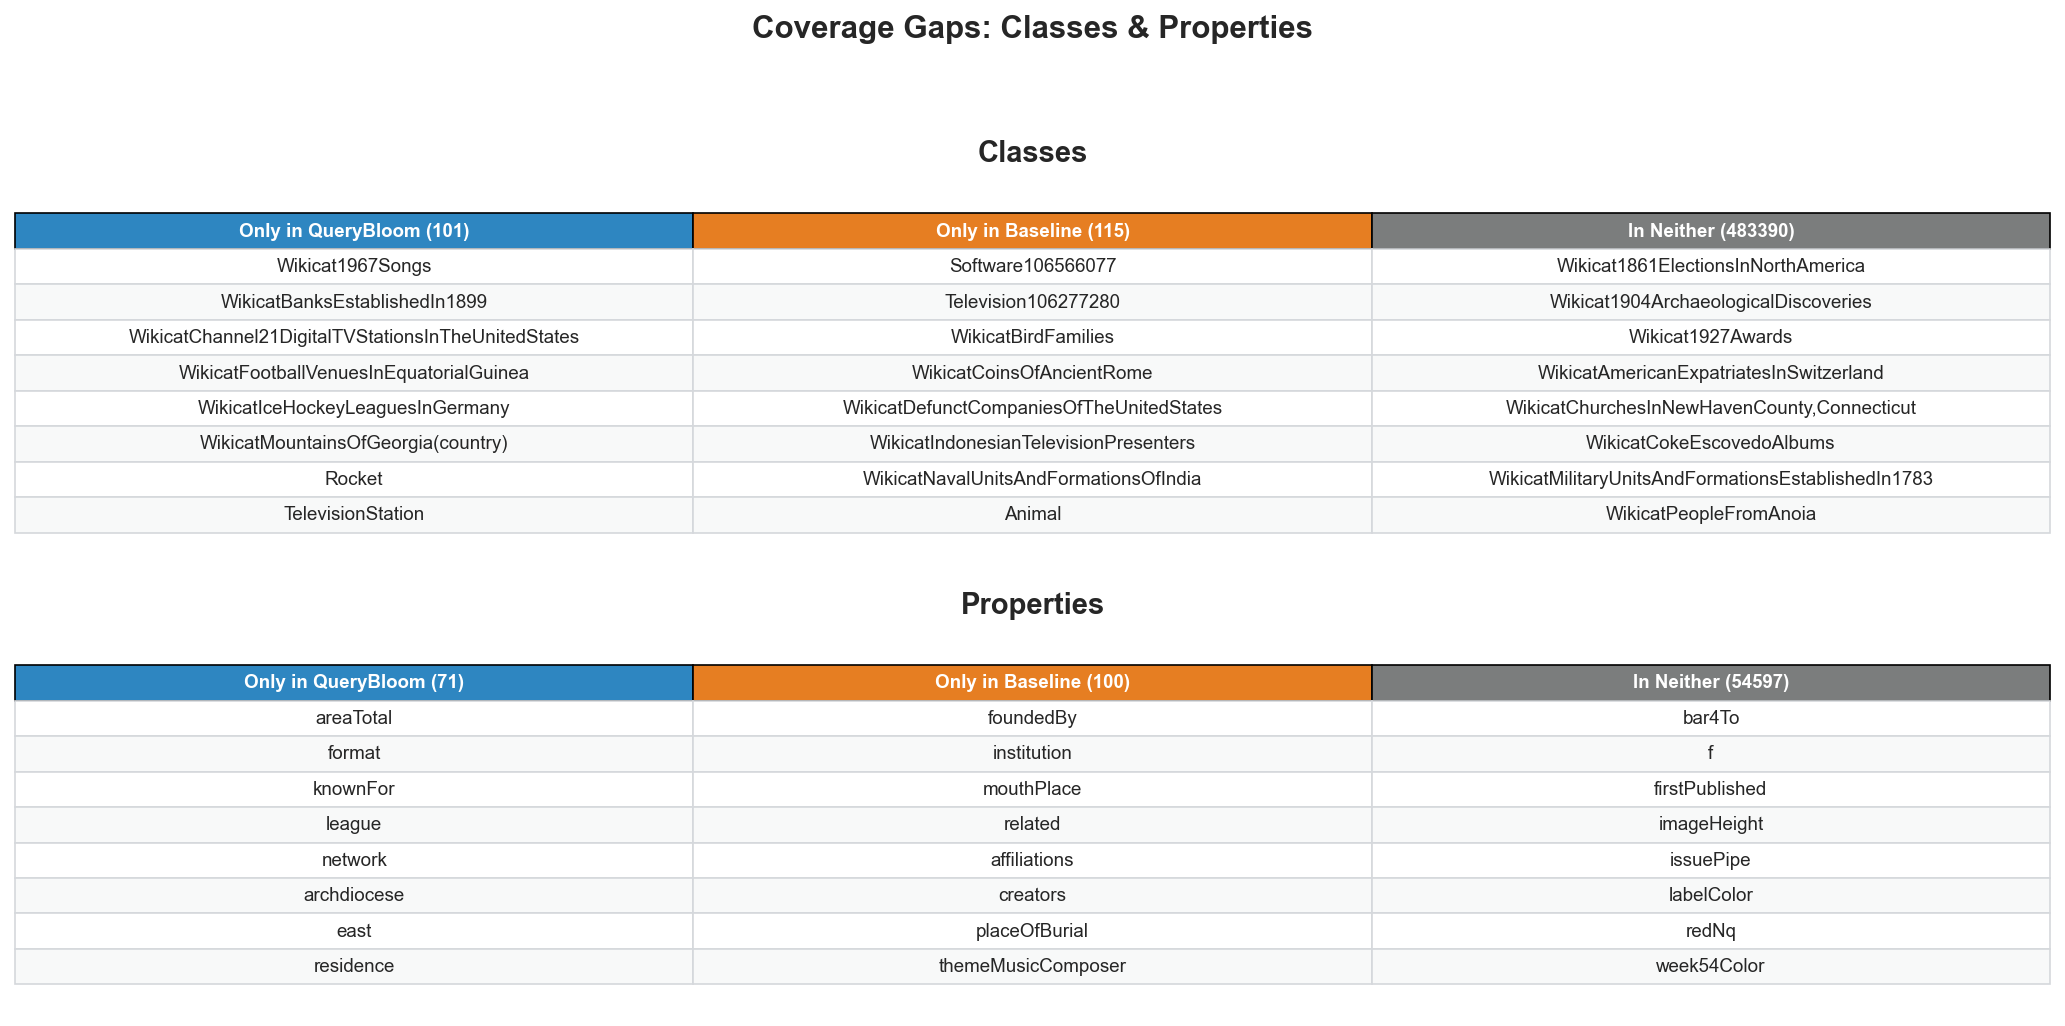

In [7]:
plot_coverage_table(queries1, queries2, kg_name, label1, label2, endpoint=endpoint)